# PCA(Principal Component Analysis)

### Import Libraries

In [2]:
import sklearn
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Generate data

In [3]:
# generating random data in 4 columns(features)
# columns 3 and 4 are derived from columns 1 and 2 with some noise addition

np.random.seed(42)
X = np.random.normal(size =(100,4))
X[:,2] = 3 * X[:,0] - 2 * X[:,1] + np.random.normal(0, 0.1, 100)
X[:,3] = 1.5 * X[:,0] - 0.5 * X[:,1] + np.random.normal(0, 0.1, 100)

# de-mean each column(feature)
X = X - np.mean(X, axis = 0)

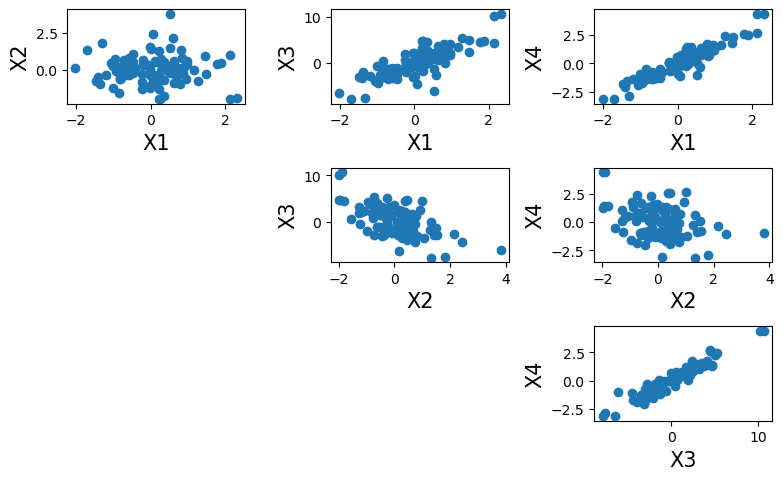

In [4]:
plt.figure(figsize =(10,6))

for i in range(4):
    for j in range(4):
        if j>i:
            plt.subplot(4,4, 4*i + j + 1)                        # plt.subplot() - notice difference with subplots()
            plt.scatter(X[:,i],X[:,j])
            plt.xlabel('X'+ str(i+1),fontsize=15)
            plt.ylabel('X'+ str(j+1),fontsize=15)
plt.tight_layout()            

<Axes: >

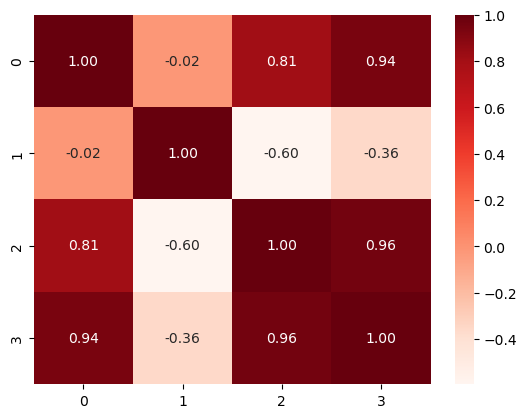

In [5]:
sns.heatmap(pd.DataFrame(X).corr(),annot= True,cmap = 'Reds', fmt ='0.2f')

### PCA Implementation

In [6]:
#---------------------------------------------------------------------------------------------------------------
# Initialize the model --> fit
#---------------------------------------------------------------------------------------------------------------

pca = PCA(n_components=4)                            # PCA()
pca.fit(X)                                           # pca.fit()

PCA(n_components=4)

### PCA Attributes

In [7]:
# eigenvalues are variances

pca.explained_variance_                 # pca.explained_variance_  : these are eigenvalues

pca.explained_variance_ratio_           # pca.explained_variance_ratio_

array([9.31067369e-01, 6.83109955e-02, 5.79633929e-04, 4.20014945e-05])

In [8]:
pca.components_.T      # pca.components_.T - each column represent eigenvector/PCA

array([[ 0.19859984,  0.48744109,  0.14424245,  0.83794594],
       [-0.14839987,  0.79516323,  0.33283898, -0.48467632],
       [ 0.89284655, -0.11957037,  0.38130239, -0.20769318],
       [ 0.37597956,  0.34032271, -0.85030631, -0.14070895]])

## Can we do this by hand?

In [9]:
# closed form of covariance matrix
# reshape(-1, 1) results in an array with a single column and multiple rows (a column vector), 
# while reshape(1, -1) results in an array with a single row and multiple columns (a row vector)

a =  np.array([X[i].reshape(-1,1)@X[i].reshape(1,-1) for i in range(100)])
cov_matrix = np.sum(a, axis = 0)/100

**there is an easy way to understand array operations across axis , lets say a = [100,4,4] matrix then any operation across axois =0 means removing this axis and getting [4,4] matrix**

In [11]:
# eigenvalues and eigenvectors
eig_val_vec = np.linalg.eig(cov_matrix)  

In [12]:
# eigenvalues
eig_val_vec[0]

# each column shows eigenvector
eig_val_vec[1]

array([[ 0.19859984, -0.48744109, -0.83794594, -0.14424245],
       [-0.14839987, -0.79516323,  0.48467632, -0.33283898],
       [ 0.89284655,  0.11957037,  0.20769318, -0.38130239],
       [ 0.37597956, -0.34032271,  0.14070895,  0.85030631]])

In [13]:
ordering = np.argsort(eig_val_vec[0])[::-1]
eig_val_vec[1][:,ordering]

array([[ 0.19859984, -0.48744109, -0.14424245, -0.83794594],
       [-0.14839987, -0.79516323, -0.33283898,  0.48467632],
       [ 0.89284655,  0.11957037, -0.38130239,  0.20769318],
       [ 0.37597956, -0.34032271,  0.85030631,  0.14070895]])